In [1]:
import sys
# Remove any cached version of the module
for key in list(sys.modules.keys()):
    if 'LearnML' in key:
        del sys.modules[key]
        

In [2]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

# Verify path
print("Path added:", Path.cwd().parent)
#the previous lines is necessary to ensure that the LearnML library is correctly imported and used in the notebook, allowing for testing and experimentation with the regression models and their associated functions.

from LearnML.supervised.svm import LinearSVM
from LearnML.selection.split import train_test_split
from LearnML.learn_about.learn_about import learn_about_SVM
from LearnML.metrics.metrics import classification_report



Path added: /home/mo/Documents/LearnML_Library


LEARNML | SUPPORT VECTOR MACHINES

SVM is a supervised learning algorithm that finds a decision boundary
separating different classes while maximizing the margin.

IMPORTANT CONCEPTS
------------------
1. Decision Boundary:
   w · x + b = 0

2. Margin:
   The region between the boundaries w · x + b = +1 and -1.

3. Support Vectors:
   The training samples closest to the decision boundary.
   They help determine the optimal boundary.

4. Hinge Loss:
   Penalizes samples that are misclassified or inside the margin.

5. Kernel Trick:
   When data is not linearly separable, a kernel function measures
   similarity between samples in an implicit higher-dimensional space.

   Instead of explicitly transforming every sample, the kernel computes
   similarities directly.

COMMON KERNELS
--------------
Linear:       K(x, z) = x · z
Polynomial:   K(x, z) = (x · z + c)^d
RBF:          K(x, z) = exp(-gamma * ||x - z||²)

WHY USE A KERNEL?
-----------------
A linear SVM learns a straight decision b

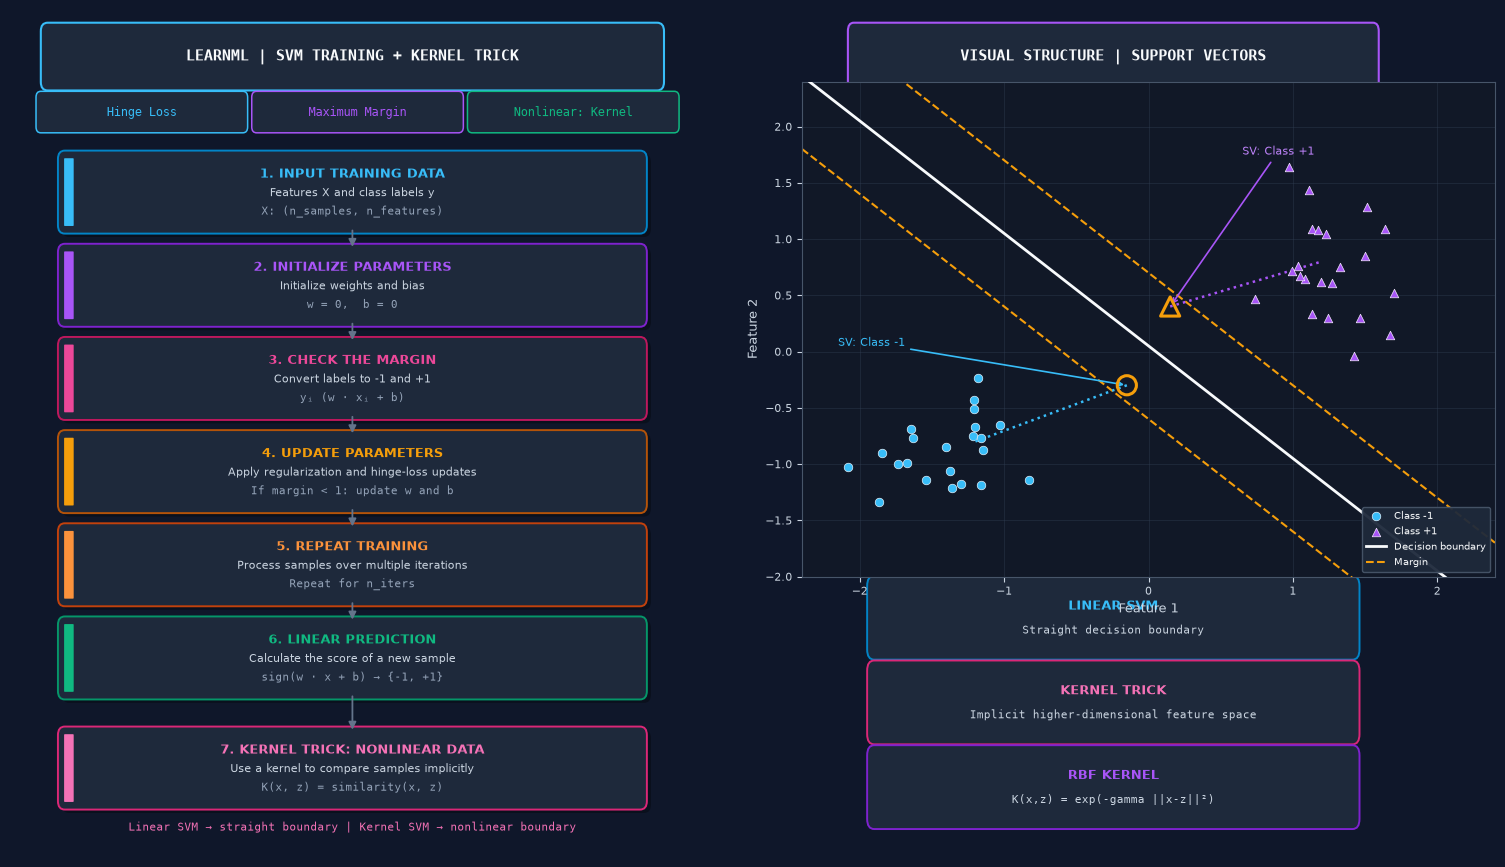

In [3]:
learn_about_SVM()

In [8]:
from sklearn.datasets import make_classification


from sklearn.datasets import make_classification

# Generate 2000 samples with single cluster per class and strong separation
X, y = make_classification(
    n_samples=2000,         # Total number of rows/samples
    n_features=10,          # Total number of input features
    n_informative=8,        # Informative features (8 out of 10)
    n_redundant=1,          # Redundant features (linear combinations)
    # Remaining 1 feature is pure random noise
    n_classes=2,            # Number of target categories
    n_clusters_per_class=1, # One unimodal cluster per class
    class_sep=1.00,         # Wide separation between class clusters
    weights=[0.55, 0.45],   # Class balance (55%, 45%)
    flip_y=0.02,            # 2% random label noise (0.0 for clean labels)
    random_state=42         # Seed for reproducibility
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)



Text(0.5, 1.0, 'Training Data Distribution')

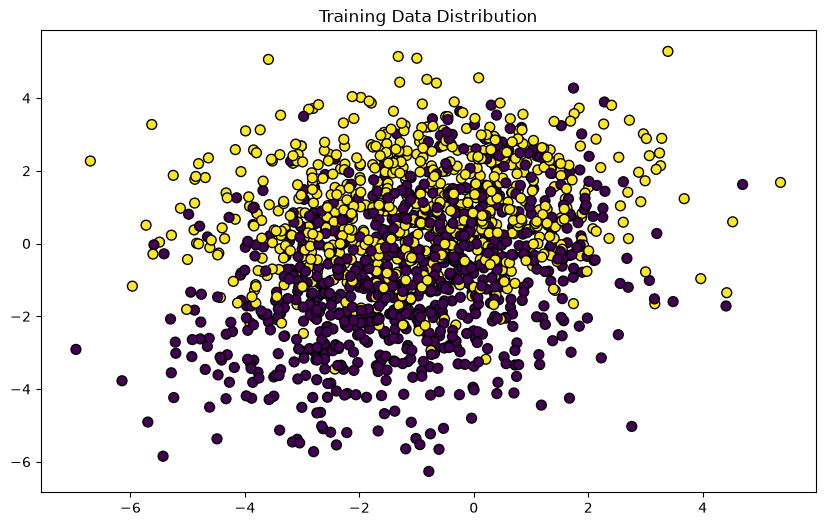

In [9]:
#visualize the data distribution
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='viridis', edgecolor='k', s=50)
plt.title('Training Data Distribution')     

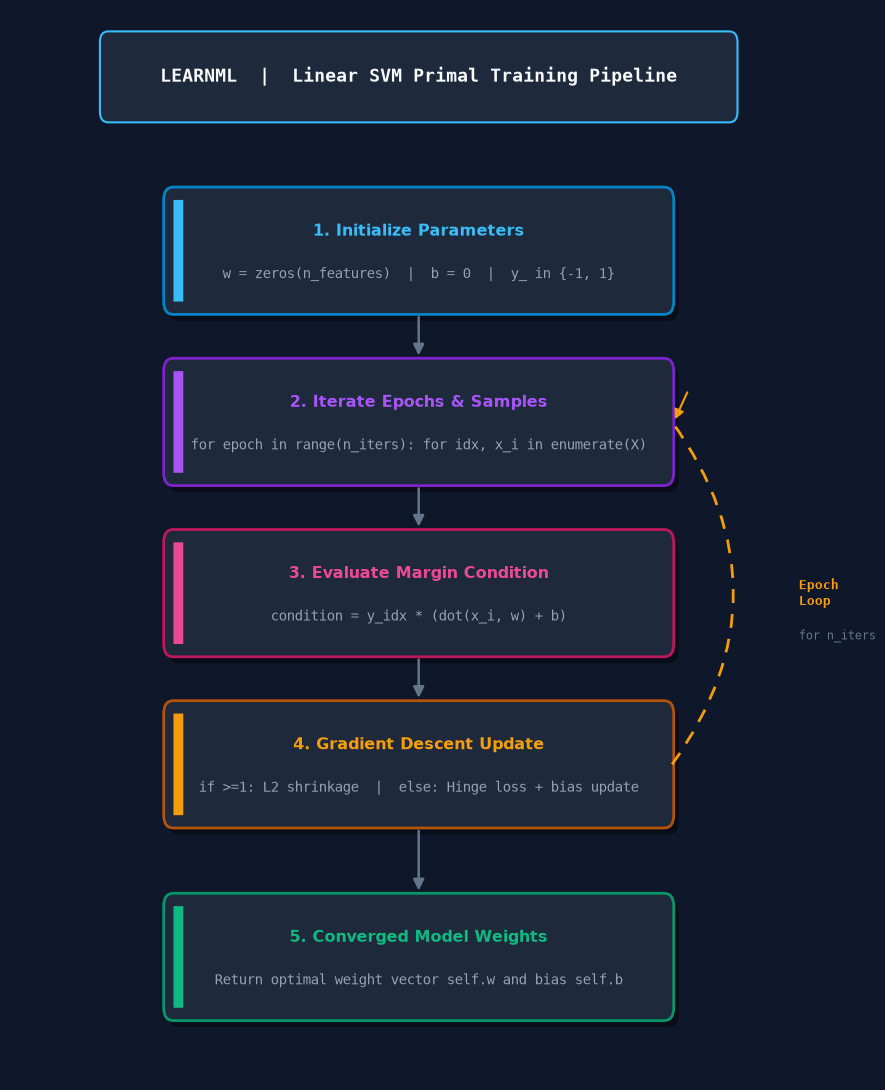

In [11]:
svm_model= LinearSVM(learning_rate=0.01, n_iters=1000)
svm_model.fit(X_train, y_train)

In [12]:
predictions = svm_model.predict(X_test)
predictions

array([-1., -1., -1., -1.,  1., -1., -1.,  1., -1., -1., -1., -1.,  1.,
        1., -1., -1., -1., -1., -1.,  1.,  1.,  1.,  1., -1.,  1.,  1.,
       -1.,  1., -1., -1.,  1.,  1., -1.,  1.,  1., -1.,  1.,  1.,  1.,
        1., -1., -1.,  1.,  1., -1.,  1., -1.,  1.,  1., -1., -1., -1.,
       -1., -1.,  1.,  1.,  1.,  1., -1.,  1.,  1., -1.,  1., -1., -1.,
        1.,  1.,  1., -1., -1.,  1., -1., -1., -1.,  1.,  1.,  1., -1.,
        1., -1.,  1., -1.,  1., -1.,  1., -1., -1.,  1., -1., -1.,  1.,
        1.,  1.,  1., -1.,  1.,  1., -1., -1., -1., -1.,  1.,  1., -1.,
       -1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1., -1., -1., -1., -1.,
       -1., -1.,  1.,  1.,  1., -1., -1., -1., -1.,  1., -1., -1.,  1.,
       -1., -1., -1.,  1., -1., -1.,  1., -1., -1.,  1., -1.,  1., -1.,
       -1., -1., -1.,  1., -1.,  1., -1., -1., -1.,  1., -1., -1., -1.,
        1.,  1., -1., -1., -1.,  1.,  1., -1., -1.,  1.,  1.,  1., -1.,
        1., -1., -1., -1., -1., -1., -1.,  1., -1.,  1.,  1., -1

In [13]:
classification_report(y_test,predictions)

Accuracy: 0.4325
Precision: 0.9558011049723757
Recall: 1.0
F1 Score: 0.9774011299435028
